<a href="https://colab.research.google.com/github/Migue0110/ACA2_Aprendizaje_Automatico/blob/main/ACA2_Aprendizaje_Automatico.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##**ACA 2 – Aprendizaje Automático**
---

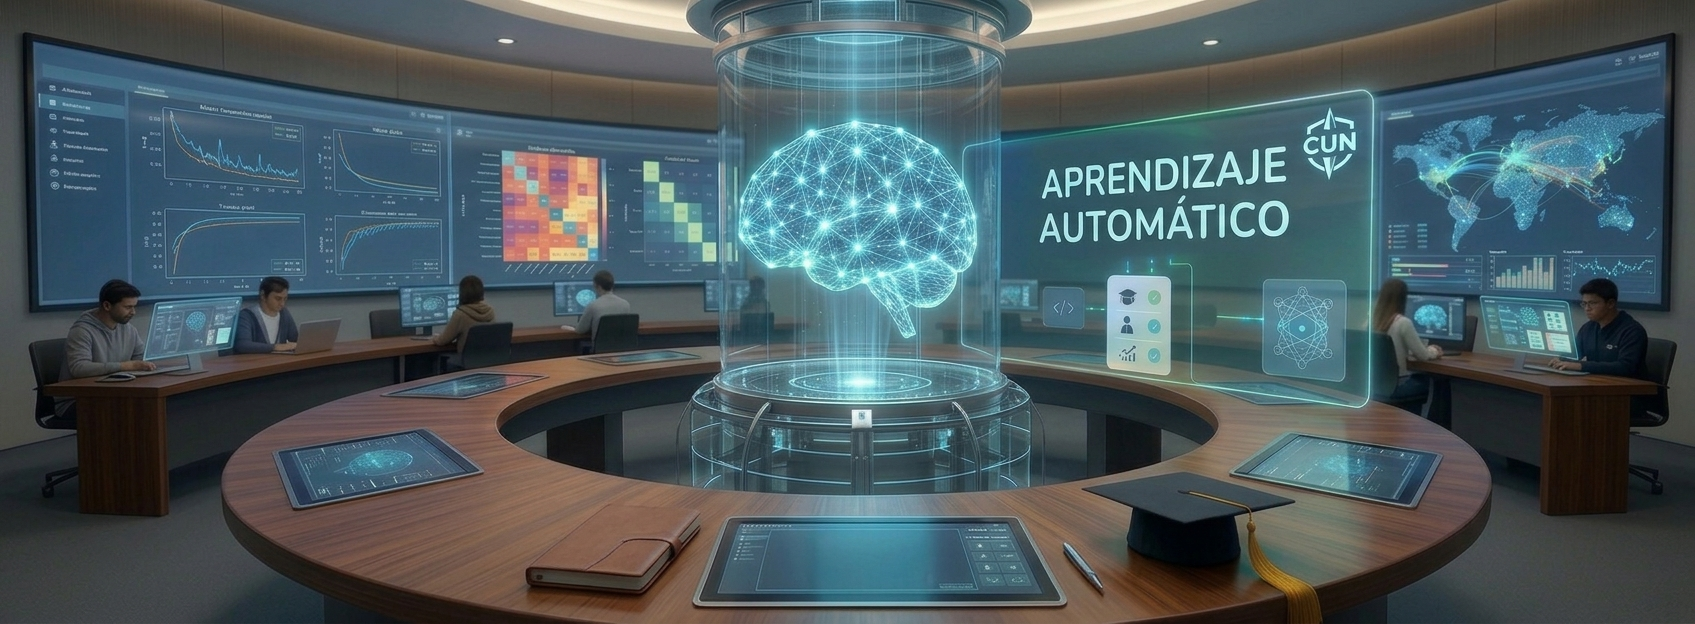

##**Integrantes**

>- Johnny Alirio Blanquicett Cardona.
>- Miguel Orlando Mora Moreno.
>- Ramón Benjamín Buelvas Sierra.
>- Rubby Yesenia Parrado Rodríguez.

### 1. Importación de librerías
---

Se importan las librerías necesarias para la manipulación y análisis de datos, la visualización, el entrenamiento y la evaluación de modelos de Machine Learning, así como la gestión de archivos y la configuración del entorno de trabajo.

In [ ]:
#Importación de librerias.

import sqlite3
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from pathlib import Path
import joblib


from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
import tensorflow as tf
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.models import Sequential
from tensorflow.keras.utils import to_categorical

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

### 2. Carga y Preparación del Conjunto de Datos
---

En esta sección se realiza la importación del archivo de datos correspondiente al éxito y deserción académica de los estudiantes para inicializar nuestro análisis.

In [ ]:
# Cargar el dataset

#from google.colab import drive
from google.colab import files

#drive.mount("/content/drive")

uploaded = files.upload()
nombre_archivo = list(uploaded.keys())[0]

#ruta = Path("/content/drive/MyDrive/Aprendizaje_Automatico/ACA2/data.csv")

#if not ruta.exists():
#    raise FileNotFoundError(
#        f"No se encontró el archivo: {ruta}"
#    )

# El dataset UCI utiliza normalmente punto y coma
#df = pd.read_csv(data.csv, sep=";")

df = pd.read_csv(nombre_archivo,sep=";")

Saving data (1).csv to data (1) (1).csv


### 3. Limpieza de Datos y Normalización de Columnas
---

Se realiza un proceso de limpieza sobre los encabezados de las columnas del DataFrame para remover espacios en blanco, tabulaciones o caracteres especiales (como el Byte Order Mark `\ufeff`) que puedan dificultar la manipulación de las variables. Adicionalmente, se comprueban las dimensiones iniciales del dataset.

In [ ]:
# Limpieza de nombres de columnas (eliminación de espacios y caracteres especiales)
df.columns = [col.strip().replace('\ufeff', '').replace('\t', '') for col in df.columns]

print(f'Dimensiones del Dataset: {df.shape[0]} filas, {df.shape[1]} columnas')

Dimensiones del Dataset: 4424 filas, 37 columnas


### 4. Ingesta y Gestión de Datos con SQLite
---

Para garantizar un almacenamiento estructurado y permitir la manipulación mediante lenguaje de consulta relacional, se crea una base de datos local ligera utilizando SQLite y se almacena el conjunto de datos limpio en una tabla llamada `students`.

In [ ]:
# Ingesta y Gestión en Base de Datos SQLite
conn = sqlite3.connect('student_success.db')
df.to_sql('students', conn, if_exists='replace', index=False)
print(
    'Base de datos SQLite "student_success.db" creada e ingerida exitosamente.'
)

Base de datos SQLite "student_success.db" creada e ingerida exitosamente.


### 5. Validación y Consulta del Dataset desde SQL
---

Se ejecuta una consulta SQL agregada sobre la base de datos para obtener estadísticas descriptivas rápidas (conteo de registros, nota de admisión promedio y edad de inscripción promedio) agrupadas por la variable objetivo (`Target`).

In [ ]:
# Consulta SQL de validación y resumen por Target
query_summary = """
    SELECT Target,
           COUNT(*) as Total,
           ROUND(AVG("Admission grade"), 2) as Avg_Admission_Grade,
           ROUND(AVG("Age at enrollment"), 2) as Avg_Age
    FROM students
    GROUP BY Target
"""
df_summary = pd.read_sql(query_summary, conn)
print('\n--- Resumen Estadístico desde SQLite ---')
print(df_summary)

conn.close()


--- Resumen Estadístico desde SQLite ---
     Target  Total  Avg_Admission_Grade  Avg_Age
0   Dropout   1421               124.96    26.07
1  Enrolled    794               125.53    22.37
2  Graduate   2209               128.79    21.78


### 6. Análisis Exploratorio de Datos (EDA) - Visualización del Target
---

Se grafica la distribución de la variable objetivo (`Target`) utilizando un diagrama de barras (`countplot`) para comprender visualmente el balance de clases entre graduados, inscritos y desertores académicos.

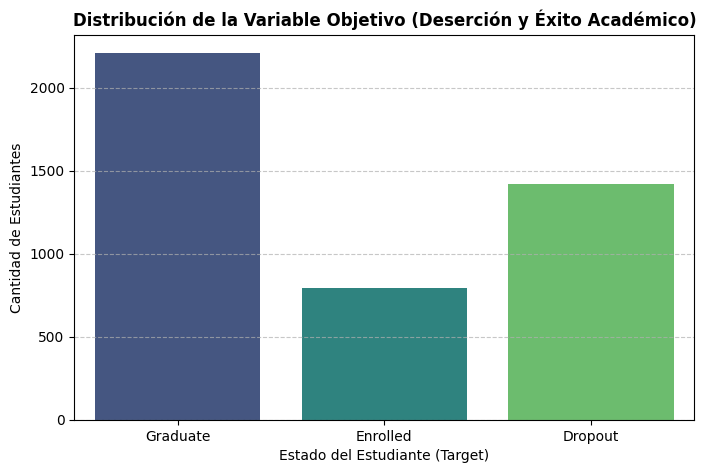

In [ ]:
# Análisis Exploratorio de Datos (EDA) - Distribución del Target
plt.figure(figsize=(8, 5))
sns.countplot(
    data=df,
    x='Target',
    order=['Graduate', 'Enrolled', 'Dropout'],
    palette='viridis',
)
plt.title(
    'Distribución de la Variable Objetivo (Deserción y Éxito Académico)',
    fontsize=12,
    weight='bold',
)
plt.xlabel('Estado del Estudiante (Target)', fontsize=10)
plt.ylabel('Cantidad de Estudiantes', fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

### 7. Extracción de Características y Definición de Variables
---

Se extraen los registros finales de la base de datos SQLite y se separan las variables predictoras (características `X`) de la etiqueta que deseamos predecir (variable objetivo `y`).

In [ ]:
conn = sqlite3.connect('student_success.db')
df = pd.read_sql('SELECT * FROM students', conn)
conn.close()

# Separar características (X) y variable objetivo (y)
X = df.drop(columns=['Target'])
y_raw = df['Target']

### 8. Codificación de Etiquetas y Partición del Dataset
---

Se codifican los valores categóricos del target a valores numéricos enteros utilizando `LabelEncoder` y posteriormente a vectores binarios utilizando codificación One-Hot (`to_categorical`). Finalmente, se divide el conjunto de datos en un 80% para entrenamiento y un 20% para pruebas de manera estratificada.

In [ ]:
# Codificación de etiquetas y Partición Train/Test
le = LabelEncoder()
y_encoded = le.fit_transform(y_raw)
y_categorical = to_categorical(y_encoded)

print('Clases codificadas:', dict(zip(le.classes_, range(len(le.classes_)))))

X_train, X_test, y_train, y_test = train_test_split(
    X, y_categorical, test_size=0.2, random_state=42, stratify=y_encoded
)

Clases codificadas: {'Dropout': 0, 'Enrolled': 1, 'Graduate': 2}


### 9. Escalado de Características
---

Dado que las redes neuronales artificiales son sensibles a la escala de las variables numéricas de entrada, se aplica un escalado estándar (`StandardScaler`) para normalizar las características y asegurar una rápida convergencia del optimizador.

In [ ]:
# Escalado de características (StandardScaler)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f'Dimensiones Entrenamiento: {X_train_scaled.shape}')
print(f'Dimensiones Prueba: {X_test_scaled.shape}')

Dimensiones Entrenamiento: (3539, 36)
Dimensiones Prueba: (885, 36)


### 10. Arquitectura del Perceptrón Multicapa (MLP)
---

Se construye un modelo de Red Neuronal Artificial secuencial con capas densamente conectadas y capas de regularización Dropout para prevenir el sobreajuste. Se define la función de pérdida `categorical_crossentropy` idónea para la clasificación multiclase.

In [ ]:
# Construcción de la Arquitectura del Perceptrón Multicapa (MLP)
model = Sequential(
    [
        Input(shape=(X_train_scaled.shape[1],)),
        Dense(128, activation='relu'),
        Dropout(0.3),  # Regularización para evitar overfitting
        Dense(64, activation='relu'),
        Dropout(0.2),
        Dense(3, activation='softmax'),  # 3 clases de salida (Multiclase)
    ]
)

# Compilación del modelo
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy'],
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 128)            │         4,736 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,187 (51.51 KB)

 Trainable params: 13,187 (51.51 KB)

 Non-trainable params: 0 (0.00 B)

### 11. Entrenamiento y Fine-Tuning del Modelo
---

Se entrena el modelo de red neuronal durante 40 épocas utilizando un tamaño de lote (batch size) de 32 y un 20% de datos destinados a la validación durante cada época de aprendizaje.

In [ ]:
# Entrenamiento del Modelo (Fine-Tuning / Training)
EPOCHS = 40
BATCH_SIZE = 32

history = model.fit(
    X_train_scaled,
    y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_split=0.2,
    verbose=1,
)

Epoch 1/40
89/89 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.6394 - loss: 0.8595 - val_accuracy: 0.7415 - val_loss: 0.6437
Epoch 2/40
89/89 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7238 - loss: 0.6742 - val_accuracy: 0.7669 - val_loss: 0.5832
Epoch 3/40
89/89 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7503 - loss: 0.6254 - val_accuracy: 0.7754 - val_loss: 0.5736
Epoch 4/40
89/89 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7531 - loss: 0.6108 - val_accuracy: 0.7726 - val_loss: 0.5665
Epoch 5/40
89/89 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7665 - loss: 0.5872 - val_accuracy: 0.7797 - val_loss: 0.5655
Epoch 6/40
89/89 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7704 - loss: 0.5742 - val_accuracy: 0.7684 - val_loss: 0.5711
Epoch 7/40
89/89 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7651 - loss: 0.5607 - val_accuracy: 0.7655 - val_loss: 0.5720
Epoch 8/40
89/89 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7778 - loss: 0.5535 - val_accuracy: 0.7768 - val_loss:

### 12. Evaluación Cuantitativa del Modelo
---

Evaluamos el desempeño del perceptrón entrenado utilizando el subconjunto de datos de prueba (`X_test_scaled`), midiendo la pérdida general y el porcentaje de exactitud de clasificación.

In [ ]:
# Evaluación Cuantitativa Inicial
loss, accuracy = model.evaluate(X_test_scaled, y_test, verbose=0)
print(f'\n--- RESULTADOS EN CONJUNTO DE PRUEBA ---')
print(f'Pérdida (Loss): {loss:.4f}')
print(f'Exactitud (Accuracy): {accuracy * 100:.2f}%')


--- RESULTADOS EN CONJUNTO DE PRUEBA ---
Pérdida (Loss): 0.6716
Exactitud (Accuracy): 74.69%


### 13. Curvas de Aprendizaje (Loss y Accuracy)
---

Se grafican las curvas de pérdida y exactitud a lo largo de las épocas de entrenamiento y validación para identificar posibles comportamientos de sobreajuste o subajuste en la red neuronal.

In [ ]:
# ==========================================
# FASE 4: EVALUACIÓN CUANTITATIVA Y MÉTRICAS
# ==========================================

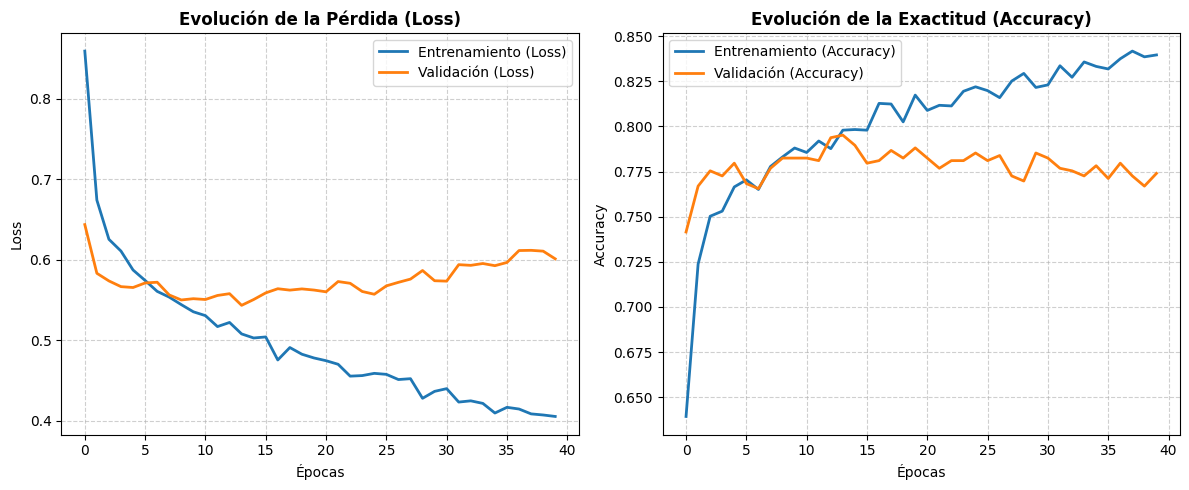

In [ ]:
#A. Gráfica de Curvas de Aprendizaje (Loss y Accuracy)
plt.figure(figsize=(12, 5))

# Gráfica de Pérdida (Loss)
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Entrenamiento (Loss)', linewidth=2)
plt.plot(history.history['val_loss'], label='Validación (Loss)', linewidth=2)
plt.title('Evolución de la Pérdida (Loss)', fontsize=12, weight='bold')  # <-- Corregido a plt.title
plt.xlabel('Épocas', fontsize=10)
plt.ylabel('Loss', fontsize=10)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

# Gráfica de Exactitud (Accuracy)
plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Entrenamiento (Accuracy)', linewidth=2)
plt.plot(history.history['val_accuracy'], label='Validación (Accuracy)', linewidth=2)
plt.title('Evolución de la Exactitud (Accuracy)', fontsize=12, weight='bold')  # <-- Corregido a plt.title
plt.xlabel('Épocas', fontsize=10)
plt.ylabel('Accuracy', fontsize=10)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

### 14. Matriz de Confusión
---

Se construye y grafica la matriz de confusión sobre las predicciones realizadas para visualizar el comportamiento detallado del modelo y entender qué clases presentan mayor confusión en el conjunto de prueba.

28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


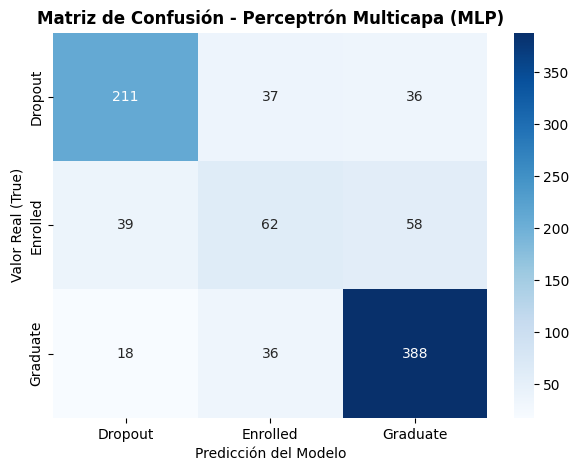

In [ ]:
#B. Generación y Visualización de la Matriz de Confusión
y_pred_classes = np.argmax(model.predict(X_test_scaled), axis=1)
y_true_classes = np.argmax(y_test, axis=1)

conf_matrix = confusion_matrix(y_true_classes, y_pred_classes)

plt.figure(figsize=(7, 5))
sns.heatmap(
    conf_matrix,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=le.classes_,
    yticklabels=le.classes_,
)
plt.title('Matriz de Confusión - Perceptrón Multicapa (MLP)', fontsize=12, weight='bold')
plt.xlabel('Predicción del Modelo', fontsize=10)
plt.ylabel('Valor Real (True)', fontsize=10)
plt.show()

### 15. Reporte Estadístico de Clasificación
---

Se genera un informe exhaustivo que calcula métricas clave para cada clase individual, tales como precisión, sensibilidad (recall) y valor F1-score.

In [ ]:
# C. Reporte de Clasificación Detallado
print('\n--- Reporte de Clasificación Detallado ---')
print(classification_report(y_true_classes, y_pred_classes, target_names=le.classes_))


--- Reporte de Clasificación Detallado ---
              precision    recall  f1-score   support

     Dropout       0.79      0.74      0.76       284
    Enrolled       0.46      0.39      0.42       159
    Graduate       0.80      0.88      0.84       442

    accuracy                           0.75       885
   macro avg       0.68      0.67      0.68       885
weighted avg       0.74      0.75      0.74       885



### 16. Exportación del Modelo y Artefactos
---

Finalmente, se almacena el modelo neuronal en formato `.keras`, junto con los serializadores del escalador de variables y el codificador de etiquetas (`.pkl`) para asegurar la reproducibilidad y despliegue del modelo en producción.

In [ ]:
# Guardar el modelo neuronal entrenado
model.save('student_mlp_model.keras')

# Guardar el scaler y el label encoder para transformar datos futuros en la app
joblib.dump(scaler, 'scaler.pkl')
joblib.dump(le, 'label_encoder.pkl')

print('Modelo, Scaler y Label Encoder guardados exitosamente en disco.')

Modelo, Scaler y Label Encoder guardados exitosamente en disco.
